## Search Engine with Tools Agents

In [20]:
## Arxiv--Research 
## Tools creation
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper


In [21]:
api_wrapper_wiki=WikipediaAPIWrapper(top_k_results=1,doc_content_chars_max=250)  # it is a wrapper for Wikipedia API used to fetch information from Wikipedia.
wiki=WikipediaQueryRun(api_wrapper=api_wrapper_wiki)  # it is a tool for Wikipedia API used to fetch information from Wikipedia.
wiki.name

'wikipedia'

In [22]:
api_wrapper_arxiv=ArxivAPIWrapper(top_k_results=1,doc_content_chars_max=250)  # it is a wrapper for Arxiv API used to fetch information from Arxiv.
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv)  # it is a tool for Arxiv API used to fetch information from Arxiv.
print(arxiv.name)

arxiv


In [23]:
tools=[wiki,arxiv]  # it is a list of tools used to fetch information from Wikipedia and Arxiv.

In [24]:
## Custom tools[RAG tool]

from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings


In [25]:
loader=WebBaseLoader("https://docs.smith.langchain.com/")
docs=loader.load()
documents=RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=0).split_documents(docs)
vectordb=FAISS.from_documents(documents,HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2"))
retriever=vectordb.as_retriever()
retriever

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2096.08it/s]


VectorStoreRetriever(tags=['FAISS', 'HuggingFaceEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x00000250B4FB5E50>, search_kwargs={})

In [26]:
## Lets convert retrieevr into a tool

from langchain_core.tools import create_retriever_tool

retriever_tool = create_retriever_tool(
    retriever,
    "langsmith-search",
    "search any information related to langsmith and langchain"
)

In [27]:
# adding all the tools into a list
tools=[wiki,arxiv,retriever_tool]  # it is a list of tools used to fetch information from Wikipedia, Arxiv and Langsmith.


In [28]:
tools

[WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'c:\\Users\\Rishabh Pandey\\Desktop\\ChatBot(Gemini+Ollama)\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=1, lang='en', load_all_available_meta=False, doc_content_chars_max=250)),
 ArxivQueryRun(api_wrapper=ArxivAPIWrapper(arxiv_search=<class 'arxiv.Search'>, arxiv_exceptions=(<class 'arxiv.ArxivError'>, <class 'arxiv.UnexpectedEmptyPageError'>, <class 'arxiv.HTTPError'>), top_k_results=1, ARXIV_MAX_QUERY_LENGTH=300, continue_on_failure=False, load_max_docs=100, load_all_available_meta=False, doc_content_chars_max=250)),
 StructuredTool(name='langsmith-search', description='search any information related to langsmith and langchain', args_schema=<class 'langchain_core.tools.retriever.RetrieverInput'>, func=<function create_retriever_tool.<locals>.func at 0x00000250B5047320>, coroutine=<function create_retriever_tool.<locals>.afunc at 0x00000250B5047D70>)]

#### Run all this tools with agents and LLM models

In [29]:
## Combining all the tools into a single agent using AgentExecutor

import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["GEMINI_API_KEY"] = os.getenv("GEMINI_API_KEY")


llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

In [32]:
## Prompt template for the agent
from langsmith import Client

client = Client()

prompt = client.pull_prompt(
    "hwchase17/openai-functions-agent",
    dangerously_pull_public_prompt=True
)
# replacement of chat prompt template

prompt.messages

[SystemMessagePromptTemplate(prompt=PromptTemplate(input_variables=[], input_types={}, partial_variables={}, template='You are a helpful assistant'), additional_kwargs={}),
 MessagesPlaceholder(variable_name='chat_history', optional=True),
 HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['input'], input_types={}, partial_variables={}, template='{input}'), additional_kwargs={}),
 MessagesPlaceholder(variable_name='agent_scratchpad')]

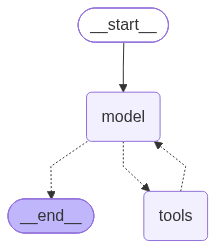

In [ ]:
## Normal Agents
from langchain.agents import create_agent

agent = create_agent(
    model=llm,
    tools=tools
)
agent

In [39]:
from langchain_classic.agents import create_openai_tools_agent

agent = create_openai_tools_agent(
    llm=llm,
    tools=tools,
    prompt=prompt
)

agent

RunnableAssign(mapper={
  agent_scratchpad: RunnableLambda(lambda x: format_to_openai_tool_messages(x['intermediate_steps']))
})
| ChatPromptTemplate(input_variables=['agent_scratchpad', 'input'], optional_variables=['chat_history'], input_types={'chat_history': list[typing.Annotated[typing.Annotated[langchain_core.messages.ai.AIMessage, Tag(tag='ai')] | typing.Annotated[langchain_core.messages.human.HumanMessage, Tag(tag='human')] | typing.Annotated[langchain_core.messages.chat.ChatMessage, Tag(tag='chat')] | typing.Annotated[langchain_core.messages.system.SystemMessage, Tag(tag='system')] | typing.Annotated[langchain_core.messages.function.FunctionMessage, Tag(tag='function')] | typing.Annotated[langchain_core.messages.tool.ToolMessage, Tag(tag='tool')] | typing.Annotated[langchain_core.messages.ai.AIMessageChunk, Tag(tag='AIMessageChunk')] | typing.Annotated[langchain_core.messages.human.HumanMessageChunk, Tag(tag='HumanMessageChunk')] | typing.Annotated[langchain_core.messages.chat

In [40]:
from langchain_classic.agents import AgentExecutor
agent_executor = AgentExecutor(
    agent=agent,
    tools=tools,
    verbose=True
)

In [43]:
agent_executor.invoke({"input":"What is Langsmith?"})



> Entering new AgentExecutor chain...

Invoking: `langsmith-search` with `{'query': 'Langsmith'}`


LangSmith Observability - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageMonitorSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangSmith ObservabilityOverviewTraceDebugObserveReferenceLangSmith ObservabilityLangSmith Observability provides full visibility into your LLM application: from individual traces to production-wide performance metrics. Traces are the record of what your agents did in production. Use them to debug failures, monitor quality, and build the datasets you evaluate against.LangSmith works with many frameworks and providers. Browse available integrations to connect your stack including OpenAI, Anthropic, CrewAI, Vercel AI SDK, Pydantic AI, and more.Get startedCreate an accountSign up at smith

{'input': 'What is Langsmith?',
 'output': '**LangSmith** is the observability, evaluation, and deployment platform built by the LangChain team to help developers build, monitor, and improve large‑language‑model (LLM) applications.  \n\n| Feature | What it does | How it’s used |\n|---------|--------------|---------------|\n| **Tracing** | Records every step an LLM app takes (e.g., prompts, responses, tool calls, chain steps). | Instrument your code with the LangSmith SDK or environment variables; view traces in the web UI. |\n| **Observability** | Provides dashboards, alerts, and metrics for overall app health and performance. | Set up alerts for latency, error rates, or prompt quality; monitor usage across teams. |\n| **Evaluation** | Run automated tests against your LLM pipelines, compare outputs, and track improvements over time. | Create evaluation suites in the UI or via code; run them on new model versions or prompts. |\n| **Prompt Engineering** | Store, version, and annotate pro

In [44]:
agent_executor.invoke({"input":"What is Machine Learning?"})



> Entering new AgentExecutor chain...
**Machine Learning (ML)** is a subfield of artificial intelligence that focuses on building systems that can learn from data, identify patterns, and make decisions or predictions with minimal human intervention.

### Core Concepts

| Concept | What it means | Example |
|---------|---------------|---------|
| **Learning** | The system improves its performance over time by adjusting internal parameters. | A spam filter that gets better at catching new spam emails. |
| **Model** | A mathematical representation that maps inputs to outputs. | A neural network that classifies images. |
| **Training** | The process of feeding data to the model so it can learn. | Feeding thousands of labeled photos to train a cat‑vs‑dog classifier. |
| **Features** | Input variables that describe the data. | Pixel values, word counts, sensor readings. |
| **Loss function** | A measure of how far the model’s predictions are from the true values. | Mean squared error for r

{'input': 'What is Machine Learning?',
 'output': '**Machine Learning (ML)** is a subfield of artificial intelligence that focuses on building systems that can learn from data, identify patterns, and make decisions or predictions with minimal human intervention.\n\n### Core Concepts\n\n| Concept | What it means | Example |\n|---------|---------------|---------|\n| **Learning** | The system improves its performance over time by adjusting internal parameters. | A spam filter that gets better at catching new spam emails. |\n| **Model** | A mathematical representation that maps inputs to outputs. | A neural network that classifies images. |\n| **Training** | The process of feeding data to the model so it can learn. | Feeding thousands of labeled photos to train a cat‑vs‑dog classifier. |\n| **Features** | Input variables that describe the data. | Pixel values, word counts, sensor readings. |\n| **Loss function** | A measure of how far the model’s predictions are from the true values. | Mea

In [46]:
agent_executor.invoke({"input":"What is the paper 'Attention is all you need' about?"})



> Entering new AgentExecutor chain...

Invoking: `arxiv` with `{'query': 'Attention is all you need arxiv'}`




AttributeError: 'Search' object has no attribute 'results'